## Ερώτημα 1
### Laplacian Pyramids

<Figure size 1500x500 with 0 Axes>

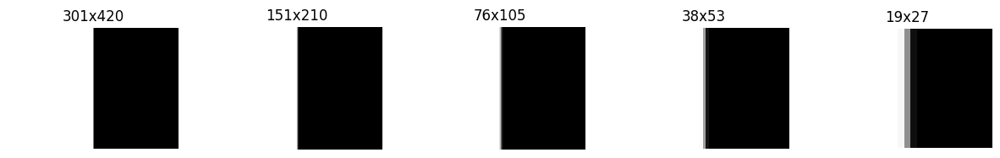

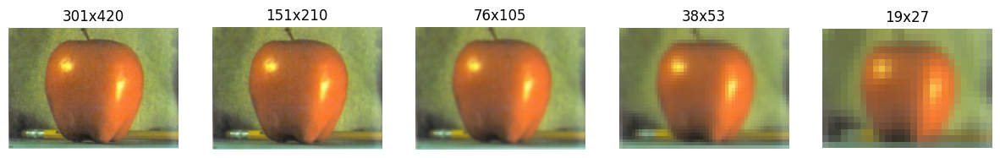

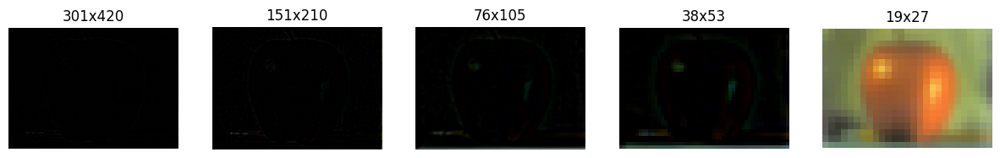

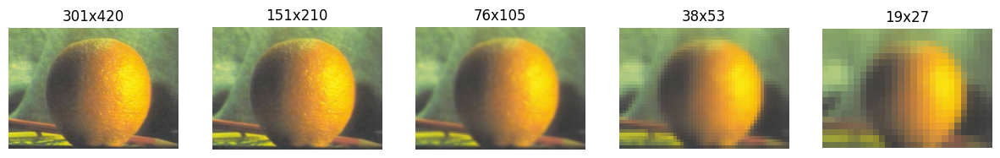

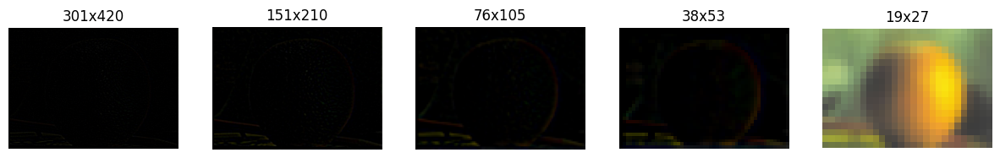

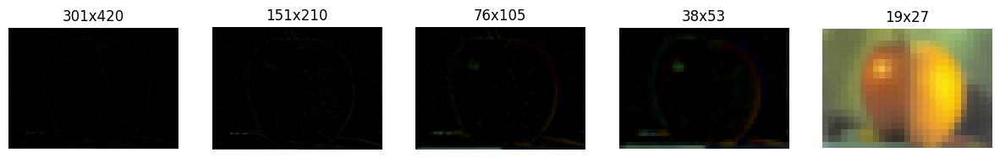

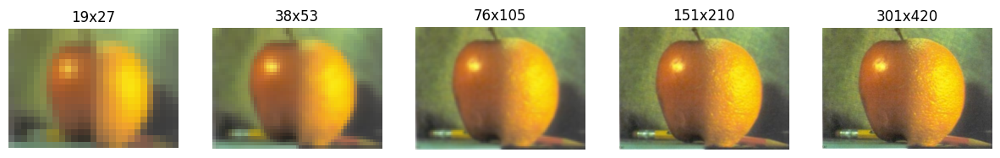

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-3.469446951953614e-18..1.0].


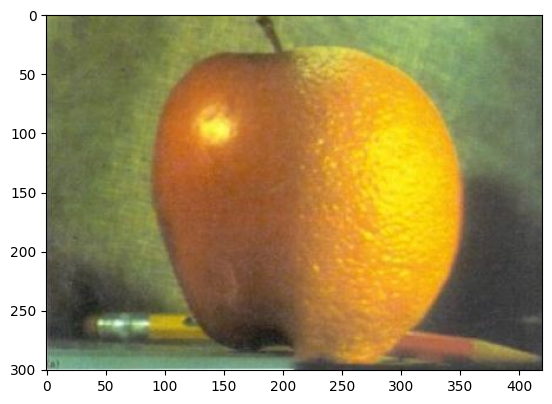

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.pyplot import figure

from helpers import get_gaussian_pyramid, get_laplacian_pyramid, show_pyramid, blend, reconstruct_from_laplacian, generate_final_pyramid

A = plt.imread('photos/apple.jpg')
I1 = A.astype(float)/255.0
B = plt.imread('photos/orange.jpg')
I2 = B.astype(float)/255.0
min_rows = min(I1.shape[0], I2.shape[0])
min_cols = min(I1.shape[1], I2.shape[1])
I1 = I1[:min_rows, :min_cols, :]
I2 = I2[:min_rows, :min_cols, :]

pyramid_size = 5
h = np.array([[1, 4, 6, 4, 1]]) / 16.0
mask = np.zeros(I1.shape)
mask[:, :min_cols//2, :] = 1


plt.figure(figsize=(15, 5))
mask_pyramid = get_gaussian_pyramid(mask, h, pyramid_size)
show_pyramid(mask_pyramid)

gaussian_pyramid = get_gaussian_pyramid(I1, h, pyramid_size)
laplacian_pyramid = get_laplacian_pyramid(gaussian_pyramid, h, pyramid_size)

gaussian_pyramid2 = get_gaussian_pyramid(I2, h, pyramid_size)
laplacian_pyramid2 = get_laplacian_pyramid(gaussian_pyramid2, h, pyramid_size)

blend_pyramid = blend(laplacian_pyramid, laplacian_pyramid2, mask_pyramid)
final_img, reconstructed = reconstruct_from_laplacian(blend_pyramid, h)

show_pyramid(gaussian_pyramid)
show_pyramid(laplacian_pyramid)
show_pyramid(gaussian_pyramid2)
show_pyramid(laplacian_pyramid2)
show_pyramid(blend_pyramid)
show_pyramid(reconstructed)
plt.imshow(final_img)





## Ερώτημα 2

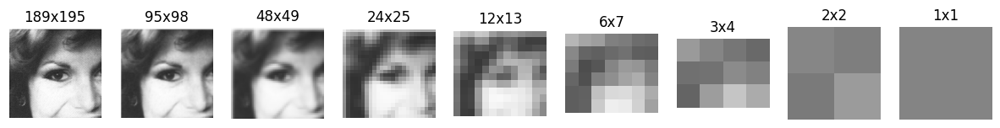

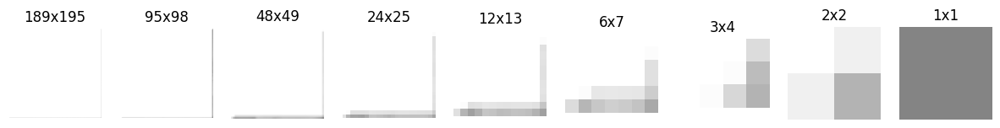

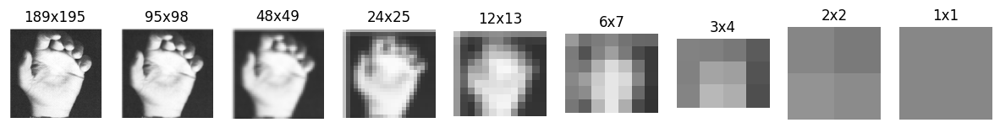

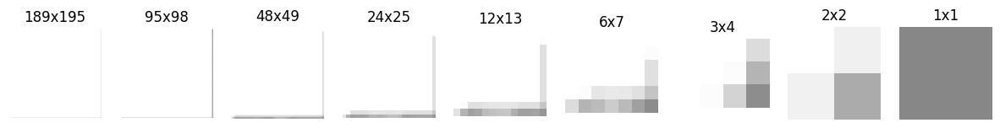

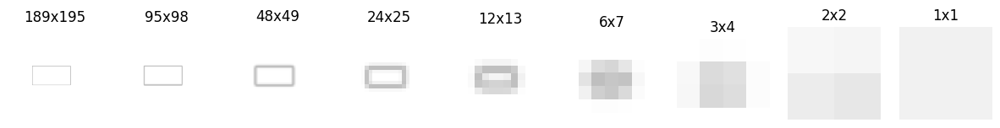

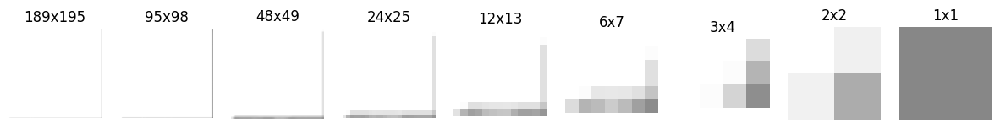

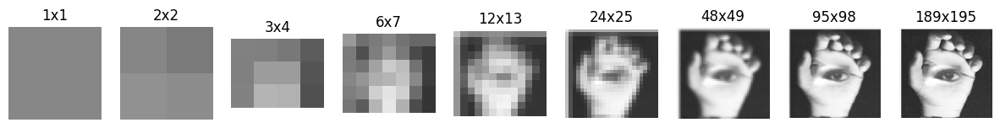

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.01618968505690843..1.0901699261377589].


final img


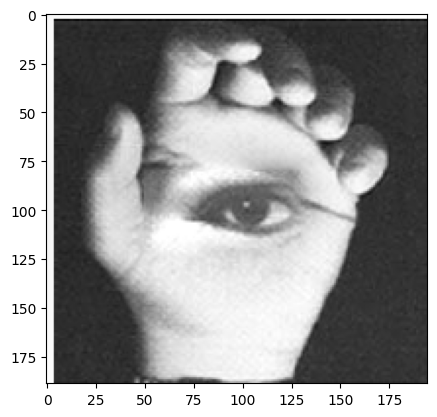

In [3]:
I1 = plt.imread('photos/woman.png')
I2 = plt.imread('photos/hand.png')
min_rows = min(I1.shape[0], I2.shape[0])
min_cols = min(I1.shape[1], I2.shape[1])
I1 = I1[:min_rows, :min_cols, :]
I2 = I2[:min_rows, :min_cols, :]

pyramid_size = 9
mask = np.zeros(I1.shape)
mask[80:120, 50:130 , :] = 1

final_img, reconstructed = generate_final_pyramid(I1, I2, h, pyramid_size, mask)
print("final img")
plt.imshow(final_img)

# plt.imshow(mask)

## Ερώτημα 3
### Σύνθεση

I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)


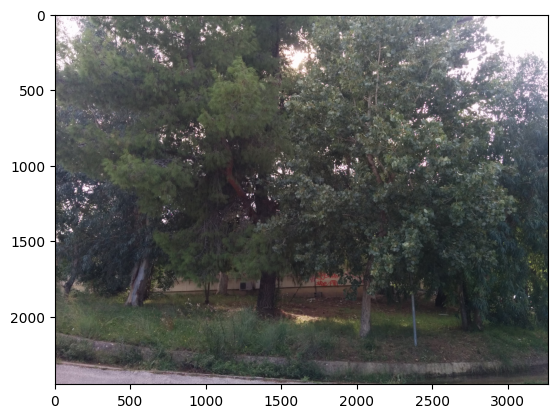

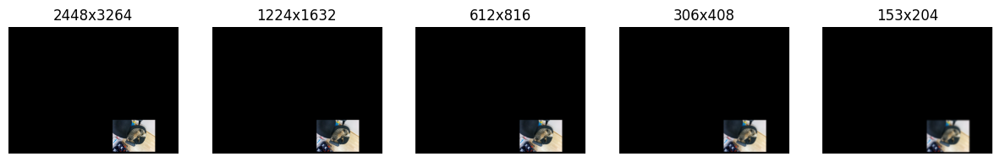

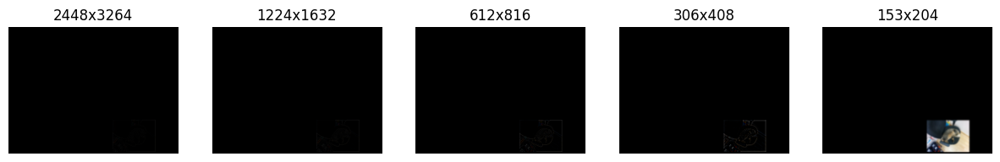

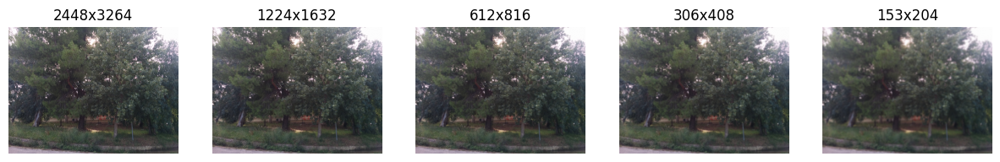

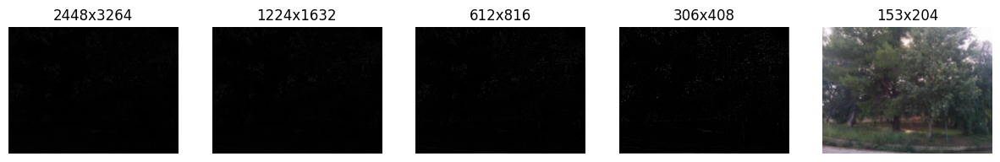

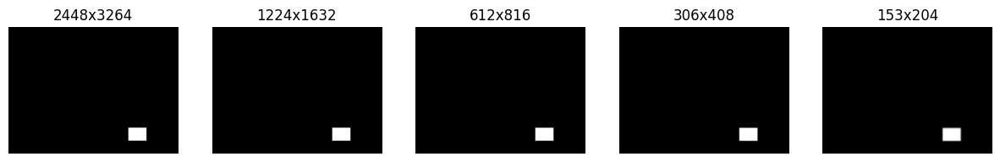

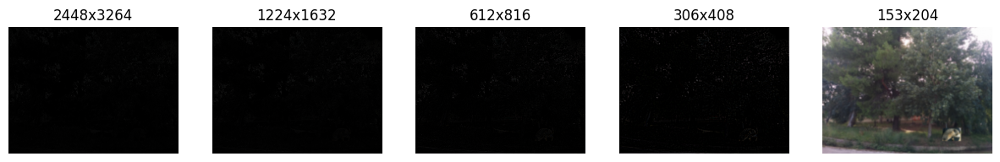

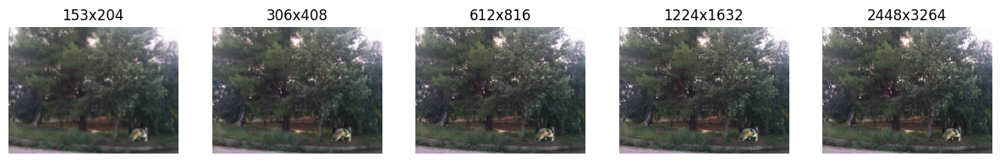

I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)


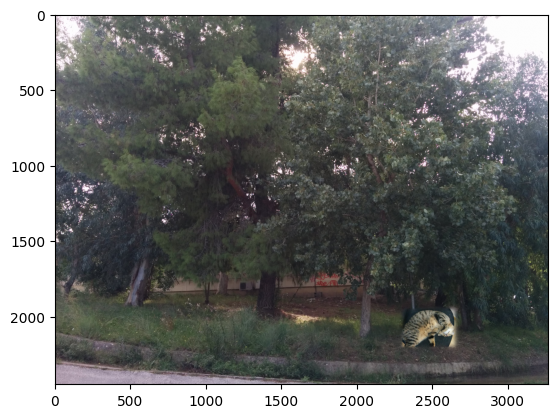

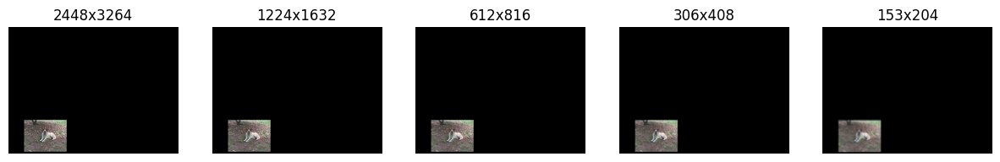

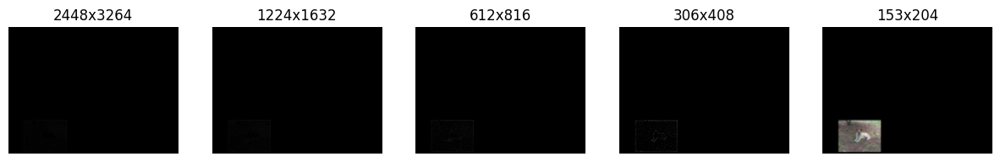

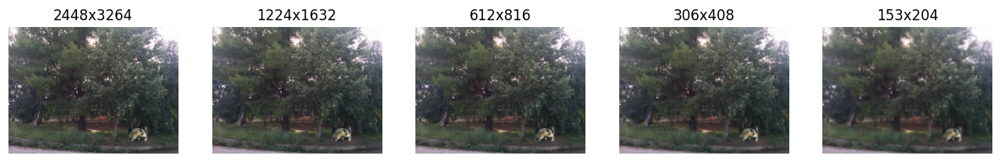

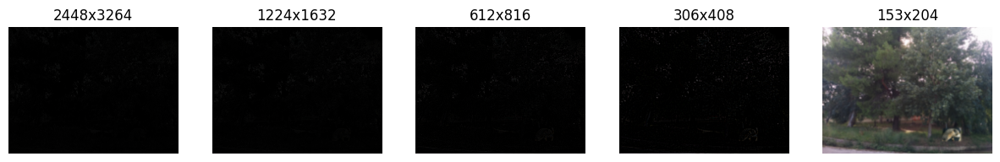

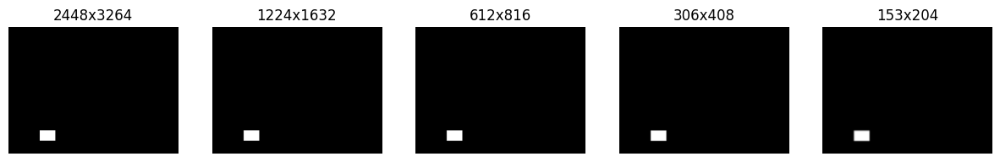

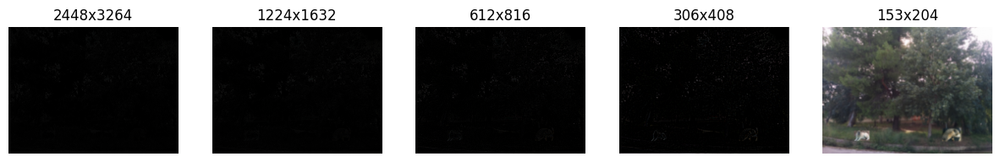

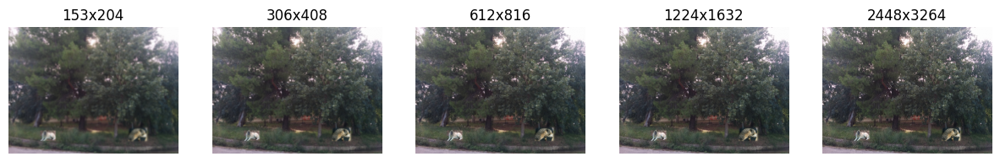

I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)
bench shapge: (2448, 3264, 3)


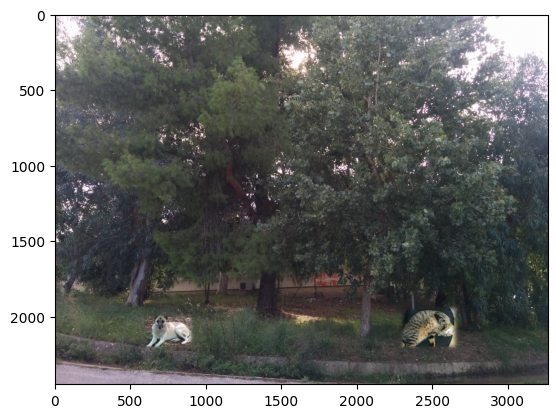

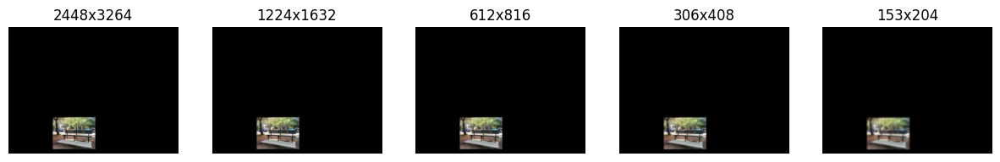

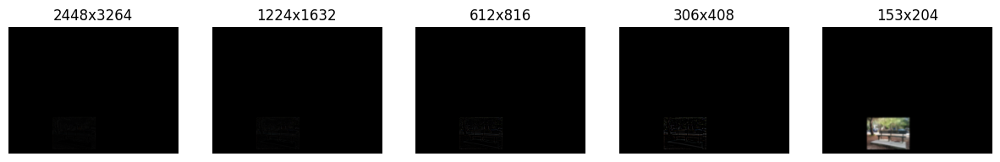

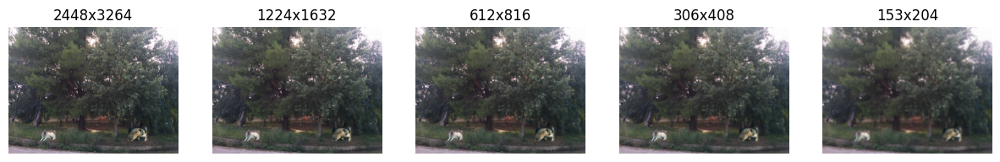

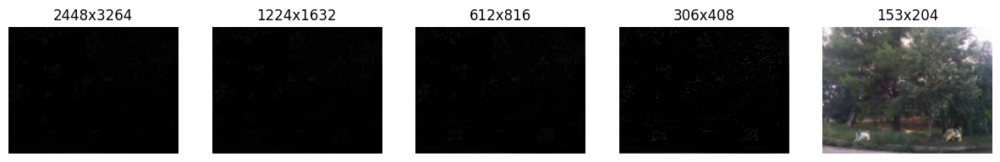

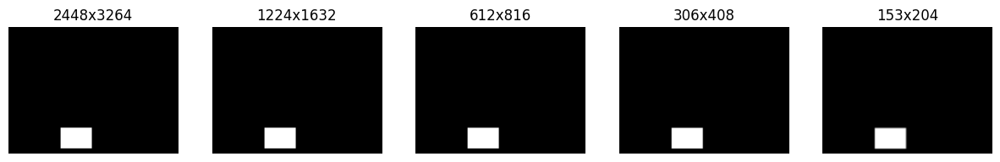

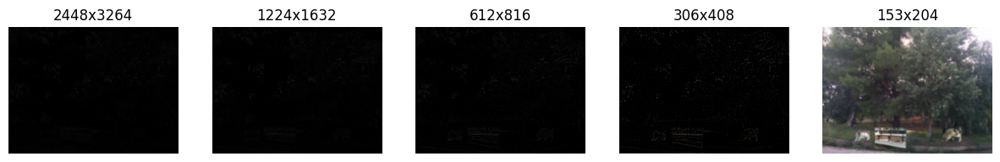

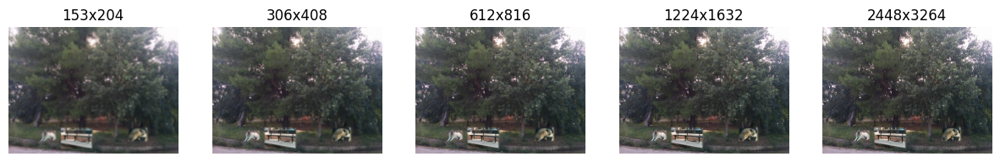

I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)


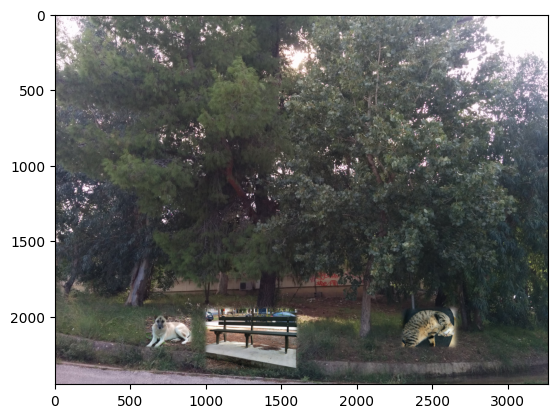

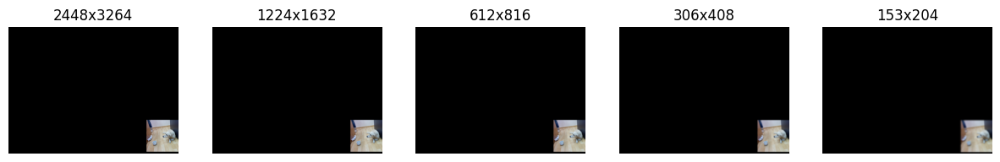

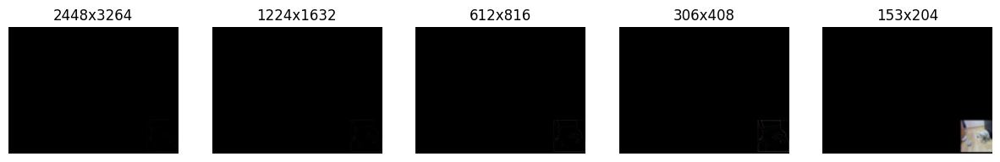

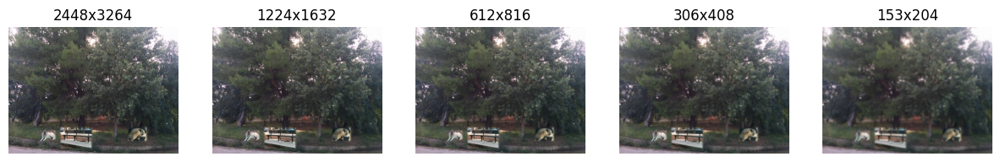

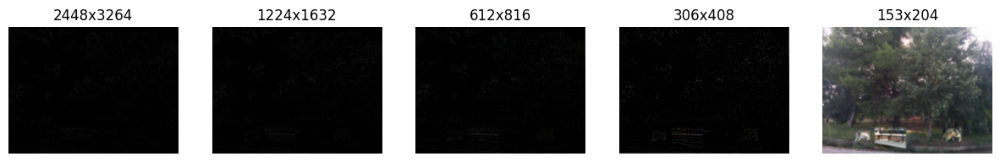

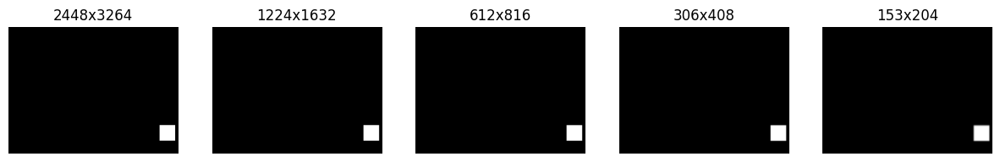

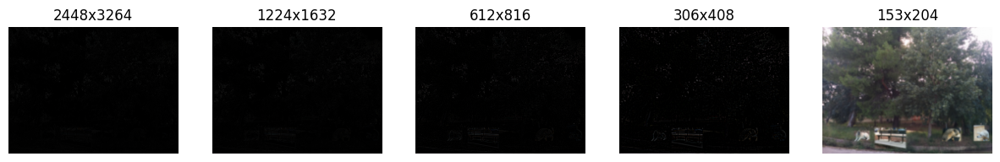

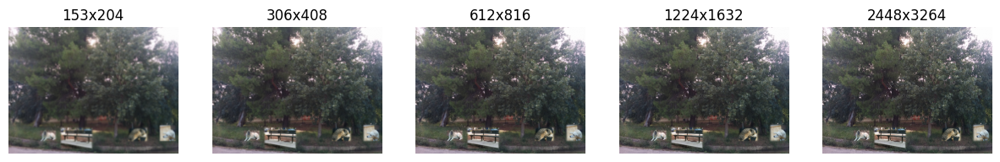

I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)
I1 shape: (2448, 3264, 3)


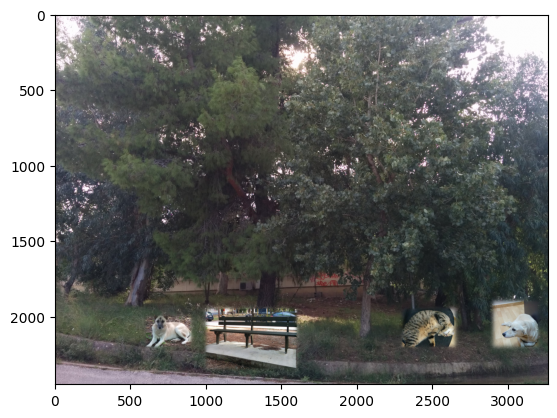

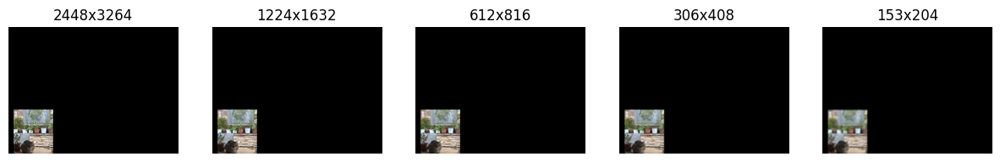

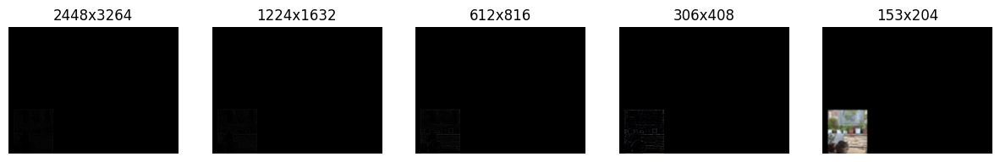

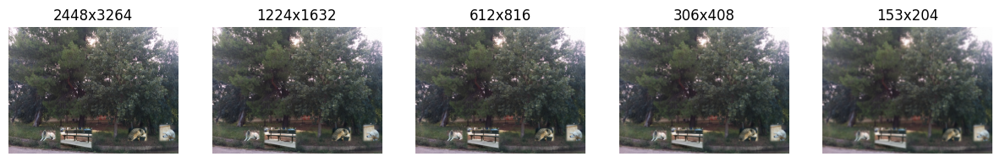

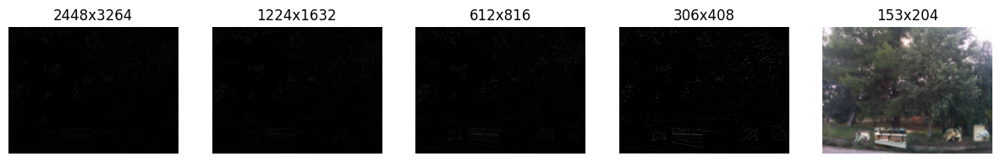

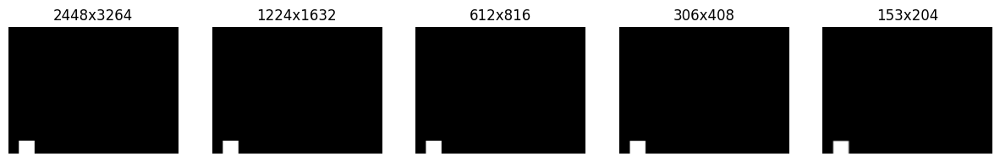

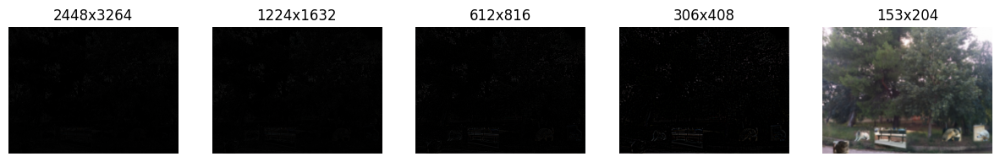

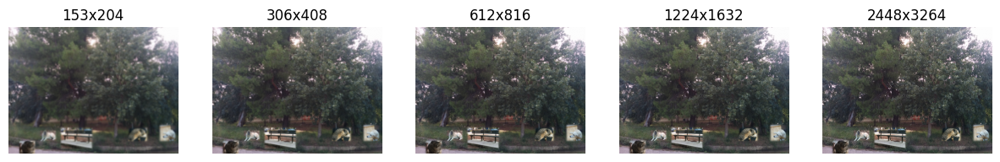

Η εικόνα αποθηκεύτηκε ως final_blended_image.png


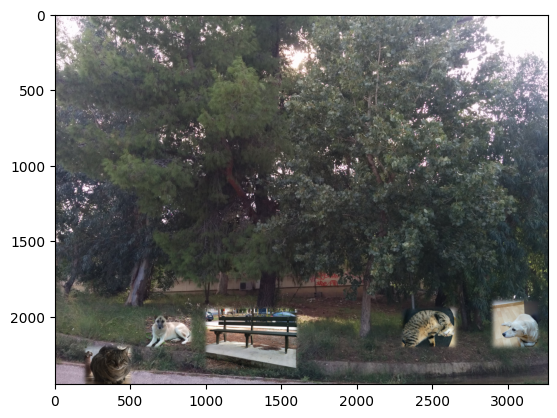

In [5]:
from helpers import downsize_and_reposition

trees = plt.imread('photos/P200.jpg')
trees = trees.astype(float)/255.0
plt.imshow(trees)
pyramid_size = 5

# place cat
cat_full = plt.imread('photos/cat.jpg')
cat_full = cat_full.astype(float)/255.0
cat = downsize_and_reposition(trees, cat_full, h, 900, (1800, 2000))
mask = np.zeros(trees.shape)
mask[1950:2200, 2300:2650, :] = 1
cat_in_trees, reconstructed = generate_final_pyramid(cat, trees, h, pyramid_size, mask, show_pyramids=True)


# place dog 1
dog1_full = plt.imread('photos/dog1.jpg')
dog1_full = dog1_full.astype(float)/255.0
dog1 = downsize_and_reposition(cat_in_trees, dog1_full, h, 900, (1800, 300))
mask = np.zeros(cat_in_trees.shape)
mask[2000:2200, 600:900, :] = 1
dog1_in_trees, reconstructed = generate_final_pyramid(dog1, cat_in_trees, h, pyramid_size, mask, show_pyramids=True)

#place bench
bench_full = plt.imread('photos/bench.jpg')
bench_full = bench_full.astype(float)/255.0
bench = downsize_and_reposition(dog1_in_trees, bench_full, h, 1000, (1750, 850))
print("bench shapge:", bench.shape)
mask = np.zeros(cat_in_trees.shape)
mask[1950:-100, 1000:1600, :] = 1
bench_in_trees, reconstructed = generate_final_pyramid(bench, dog1_in_trees, h, pyramid_size, mask, show_pyramids=True)

#place dog 2
dog2_full = plt.imread('photos/dog2.jpg')
dog2_full = dog2_full.astype(float)/255.0
dog2 = downsize_and_reposition(cat_in_trees, dog2_full, h, 900, (1800, 2650))
mask = np.zeros(cat_in_trees.shape)
mask[1900:2200, 2900:3200, :] = 1
dog2_in_trees, reconstructed = generate_final_pyramid(dog2, bench_in_trees, h, pyramid_size, mask, show_pyramids=True)

#place my image
mine_full = plt.imread('photos/mine.jpg')
mine_full = mine_full.astype(float)/255.0
mine = downsize_and_reposition(dog1_in_trees, mine_full, h, 900, (1600, 100))

mask = np.zeros(cat_in_trees.shape)
mask[2200:2500, 200:500, :] = 1
mine_in_trees, reconstructed = generate_final_pyramid(mine, dog2_in_trees, h, pyramid_size, mask, show_pyramids=True)

# Αποθήκευση στον δίσκο
plt.imsave('final_blended_image.png', np.clip(mine_in_trees, 0, 1))
print("Η εικόνα αποθηκεύτηκε ως final_blended_image.png")


